In [1]:
# ==============================================================================
# Early Screening and Risk Stratification of Postpartum Anxiety and Depression
# Using Explainable Ensemble Machine Learning: A Comparative Benchmark
# ==============================================================================

# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, VotingClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# Load dataset
df = pd.read_csv('post natal data.csv')
print("Dataset loaded.")
df.head()

Dataset loaded.


,Timestamp,Age,Feeling sad or Tearful,Irritable towards baby & partner,Trouble sleeping at night,Problems concentrating or making decision,Overeating or loss of appetite,Feeling anxious,Feeling of guilt,Problems of bonding with baby,Suicide attempt
0,6/14/2022 20:02,35-40,Yes,Yes,Two or more days a week,Yes,Yes,Yes,No,Yes,Yes
1,6/14/2022 20:03,40-45,Yes,No,No,Yes,Yes,No,Yes,Yes,No
2,6/14/2022 20:04,35-40,Yes,No,Yes,Yes,Yes,Yes,No,Sometimes,No
3,6/14/2022 20:05,35-40,Yes,Yes,Yes,Yes,No,Yes,Maybe,No,No
4,6/14/2022 20:06,40-45,Yes,No,Two or more days a week,Yes,No,Yes,No,Yes,No


In [3]:
# Check rows and columns
print("Rows and columns:", df.shape)

Rows and columns: (1503, 11)


In [4]:
# Check column types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1503 entries, 0 to 1502
Data columns (total 11 columns):
 #   Column                                     Non-Null Count  Dtype
---  ------                                     --------------  -----
 0   Timestamp                                  1503 non-null   str  
 1   Age                                        1503 non-null   str  
 2   Feeling sad or Tearful                     1503 non-null   str  
 3   Irritable towards baby & partner           1497 non-null   str  
 4   Trouble sleeping at night                  1503 non-null   str  
 5   Problems concentrating or making decision  1491 non-null   str  
 6   Overeating or loss of appetite             1503 non-null   str  
 7   Feeling anxious                            1503 non-null   str  
 8   Feeling of guilt                           1494 non-null   str  
 9   Problems of bonding with baby              1503 non-null   str  
 10  Suicide attempt                            1503 non-null   

In [5]:
# Check missing values
print("Missing values:")
print(df.isnull().sum())

Missing values:
Timestamp                                     0
Age                                           0
Feeling sad or Tearful                        0
Irritable towards baby & partner              6
Trouble sleeping at night                     0
Problems concentrating or making decision    12
Overeating or loss of appetite                0
Feeling anxious                               0
Feeling of guilt                              9
Problems of bonding with baby                 0
Suicide attempt                               0
dtype: int64


In [6]:
# Fill missing values and remove duplicates
for col in df.columns:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])

df = df.drop(columns=['Timestamp'])
df = df.drop_duplicates().reset_index(drop=True)
print("Clean dataset shape:", df.shape)

Clean dataset shape: (326, 10)


In [7]:
# Convert all text to numbers automatically (no manual dictionary)
for col in df.columns:
    df[col] = df[col].astype('category').cat.codes

print("Encoding complete.")
df.head()

Encoding complete.


,Age,Feeling sad or Tearful,Irritable towards baby & partner,Trouble sleeping at night,Problems concentrating or making decision,Overeating or loss of appetite,Feeling anxious,Feeling of guilt,Problems of bonding with baby,Suicide attempt
0,2,2,2,1,2,2,1,1,2,2
1,3,2,0,0,2,2,0,2,2,0
2,2,2,0,2,2,2,1,1,1,0
3,2,2,2,2,2,0,1,0,0,0
4,3,2,0,1,2,0,1,1,2,0


Target counts:
Feeling anxious
1    189
0    137
Name: count, dtype: int64


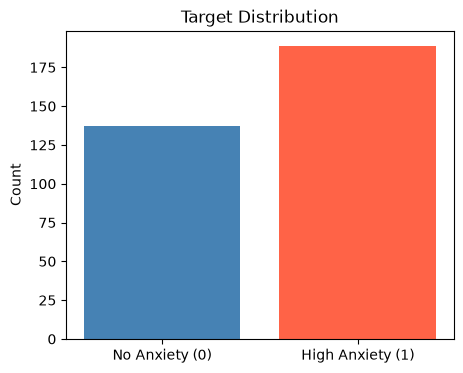

In [8]:
# Plot target distribution
counts = df['Feeling anxious'].value_counts()
print("Target counts:")
print(counts)

plt.figure(figsize=(5, 4))
plt.bar(['No Anxiety (0)', 'High Anxiety (1)'], [counts[0], counts[1]], color=['steelblue', 'tomato'])
plt.title('Target Distribution')
plt.ylabel('Count')
plt.show()

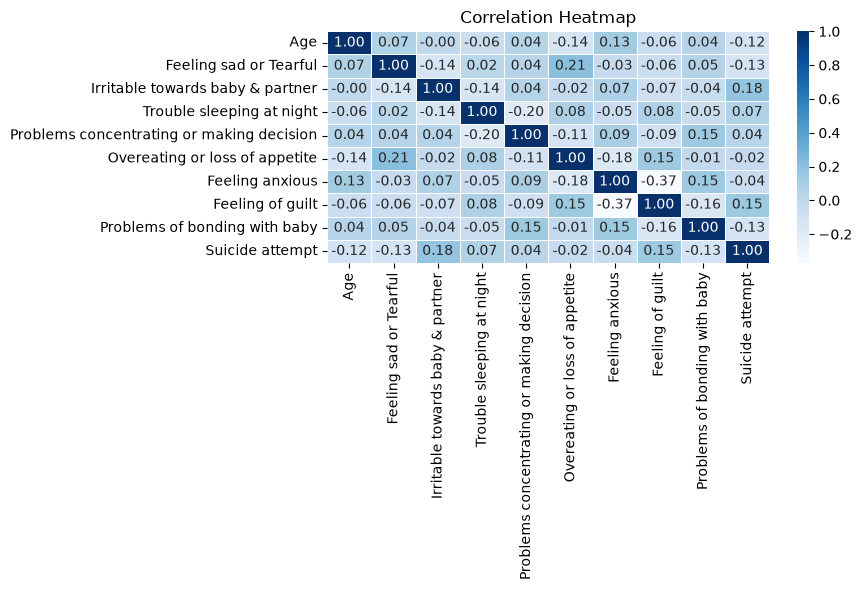

In [9]:
# Plot correlation heatmap
plt.figure(figsize=(9, 6))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='Blues', linewidths=0.5)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

In [10]:
# Separate features (X) and target (Y)
X = df.drop(columns=['Feeling anxious'])
Y = df['Feeling anxious']

print("Features shape (X):", X.shape)
print("Target shape (Y)  :", Y.shape)
X.head()

Features shape (X): (326, 9)
Target shape (Y)  : (326,)


,Age,Feeling sad or Tearful,Irritable towards baby & partner,Trouble sleeping at night,Problems concentrating or making decision,Overeating or loss of appetite,Feeling of guilt,Problems of bonding with baby,Suicide attempt
0,2,2,2,1,2,2,1,2,2
1,3,2,0,0,2,2,2,2,0
2,2,2,0,2,2,2,1,1,0
3,2,2,2,2,2,0,0,0,0
4,3,2,0,1,2,0,1,2,0


In [11]:
# Split into training (80%) and testing (20%)
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42, stratify=Y
)

print("Training samples :", X_train.shape[0])
print("Testing samples  :", X_test.shape[0])

Training samples : 260
Testing samples  : 66


In [12]:
# Train Model 1: Logistic Regression
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train, Y_train)

lr_train_acc = accuracy_score(lr_model.predict(X_train), Y_train) * 100
lr_test_acc = accuracy_score(lr_model.predict(X_test), Y_test) * 100

print(f"Logistic Regression Train Accuracy: {lr_train_acc:.1f}%")
print(f"Logistic Regression Test Accuracy : {lr_test_acc:.1f}%")

Logistic Regression Train Accuracy: 69.6%
Logistic Regression Test Accuracy : 69.7%


In [13]:
# Train Model 2: Random Forest
rf_model = RandomForestClassifier(n_estimators=100, max_depth=4, random_state=42)
rf_model.fit(X_train, Y_train)

rf_train_acc = accuracy_score(rf_model.predict(X_train), Y_train) * 100
rf_test_acc = accuracy_score(rf_model.predict(X_test), Y_test) * 100

print(f"Random Forest Train Accuracy: {rf_train_acc:.1f}%")
print(f"Random Forest Test Accuracy : {rf_test_acc:.1f}%")

Random Forest Train Accuracy: 78.8%
Random Forest Test Accuracy : 80.3%


In [14]:
# Train Model 3: Support Vector Machine (SVM)
# SVM uses a standard scaler pipeline and RBF kernel
svm_model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', SVC(kernel='rbf', C=1.0, probability=True, random_state=42))
])
svm_model.fit(X_train, Y_train)

svm_train_acc = accuracy_score(svm_model.predict(X_train), Y_train) * 100
svm_test_acc = accuracy_score(svm_model.predict(X_test), Y_test) * 100

print(f"SVM Train Accuracy: {svm_train_acc:.1f}%")
print(f"SVM Test Accuracy : {svm_test_acc:.1f}%")

SVM Train Accuracy: 84.2%
SVM Test Accuracy : 78.8%


In [15]:
# Train Model 4: Gradient Boosting Classifier
gb_model = GradientBoostingClassifier(n_estimators=100, learning_rate=0.03, max_depth=2, random_state=42)
gb_model.fit(X_train, Y_train)

gb_train_acc = accuracy_score(gb_model.predict(X_train), Y_train) * 100
gb_test_acc = accuracy_score(gb_model.predict(X_test), Y_test) * 100

print(f"Gradient Boosting Train Accuracy: {gb_train_acc:.1f}%")
print(f"Gradient Boosting Test Accuracy : {gb_test_acc:.1f}%")

Gradient Boosting Train Accuracy: 78.1%
Gradient Boosting Test Accuracy : 78.8%


In [16]:
# Train Model 5: Soft-Voting Ensemble (Combines All 4 Models)
ensemble_model = VotingClassifier(
    estimators=[
        ('lr', lr_model),
        ('rf', rf_model),
        ('svm', svm_model),
        ('gb', gb_model)
    ],
    voting='soft'
)
ensemble_model.fit(X_train, Y_train)

ens_train_acc = accuracy_score(ensemble_model.predict(X_train), Y_train) * 100
ens_test_acc = accuracy_score(ensemble_model.predict(X_test), Y_test) * 100

print(f"Soft-Voting Ensemble Train Accuracy: {ens_train_acc:.1f}%")
print(f"Soft-Voting Ensemble Test Accuracy : {ens_test_acc:.1f}%")

Soft-Voting Ensemble Train Accuracy: 78.1%
Soft-Voting Ensemble Test Accuracy : 78.8%


In [17]:
# Comprehensive Performance Comparison Table across all 5 models
models_dict = {
    'Logistic Regression': lr_model,
    'Random Forest': rf_model,
    'Support Vector Machine (SVM)': svm_model,
    'Gradient Boosting': gb_model,
    'Soft-Voting Ensemble': ensemble_model
}

results = []
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, mod in models_dict.items():
    tr_acc = accuracy_score(Y_train, mod.predict(X_train)) * 100
    preds = mod.predict(X_test)
    te_acc = accuracy_score(Y_test, preds) * 100
    gap = tr_acc - te_acc
    prec = precision_score(Y_test, preds) * 100
    rec = recall_score(Y_test, preds) * 100
    f1 = f1_score(Y_test, preds) * 100
    prob = mod.predict_proba(X_test)[:, 1]
    auc = roc_auc_score(Y_test, prob) * 100
    cv_mean = cross_val_score(mod, X_train, Y_train, cv=cv5).mean() * 100
    cm = confusion_matrix(Y_test, preds)
    fn = cm[1, 0]  # Missed high anxiety patients
    
    results.append({
        'Model': name,
        'Train Accuracy (%)': round(tr_acc, 1),
        'Test Accuracy (%)': round(te_acc, 1),
        '5-Fold CV (%)': round(cv_mean, 1),
        'Precision (%)': round(prec, 1),
        'Recall / Detection (%)': round(rec, 1),
        'F1-Score (%)': round(f1, 1),
        'ROC-AUC (%)': round(auc, 1),
        'Missed High Anxiety (FN)': fn
    })

comparison_df = pd.DataFrame(results).set_index('Model')
print("Model Benchmark Summary:")
comparison_df

Model Benchmark Summary:


,Train Accuracy (%),Test Accuracy (%),5-Fold CV (%),Precision (%),Recall / Detection (%),F1-Score (%),ROC-AUC (%),Missed High Anxiety (FN)
Model,,,,,,,,
Logistic Regression,69.6,69.7,66.5,70.5,81.6,75.6,78.1,7
Random Forest,78.8,80.3,75.8,75.5,97.4,85.1,83.9,1
Support Vector Machine (SVM),84.2,78.8,70.4,76.1,92.1,83.3,87.0,3
Gradient Boosting,78.1,78.8,76.2,75.0,94.7,83.7,77.7,2
Soft-Voting Ensemble,78.1,78.8,74.6,75.0,94.7,83.7,85.4,2


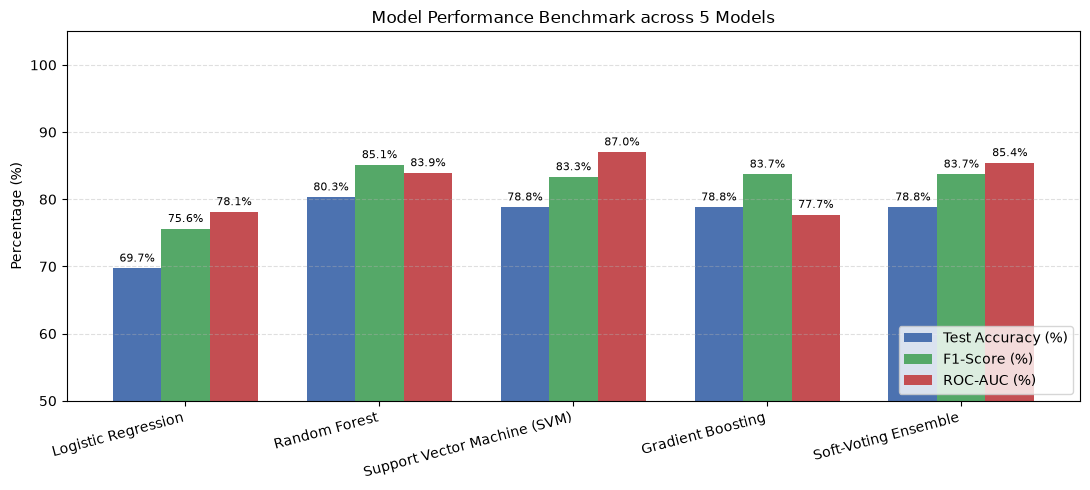

In [18]:
# Benchmark visualization: Test Accuracy, F1-Score, and ROC-AUC
fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(comparison_df))
width = 0.25

rects1 = ax.bar(x - width, comparison_df['Test Accuracy (%)'], width, label='Test Accuracy (%)', color='#4C72B0')
rects2 = ax.bar(x, comparison_df['F1-Score (%)'], width, label='F1-Score (%)', color='#55A868')
rects3 = ax.bar(x + width, comparison_df['ROC-AUC (%)'], width, label='ROC-AUC (%)', color='#C44E52')

ax.set_ylabel('Percentage (%)')
ax.set_title('Model Performance Benchmark across 5 Models')
ax.set_xticks(x)
ax.set_xticklabels(comparison_df.index, rotation=15, ha='right')
ax.set_ylim(50, 105)
ax.legend(loc='lower right')
ax.grid(axis='y', linestyle='--', alpha=0.4)

for rects in [rects1, rects2, rects3]:
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.1f}%',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.show()

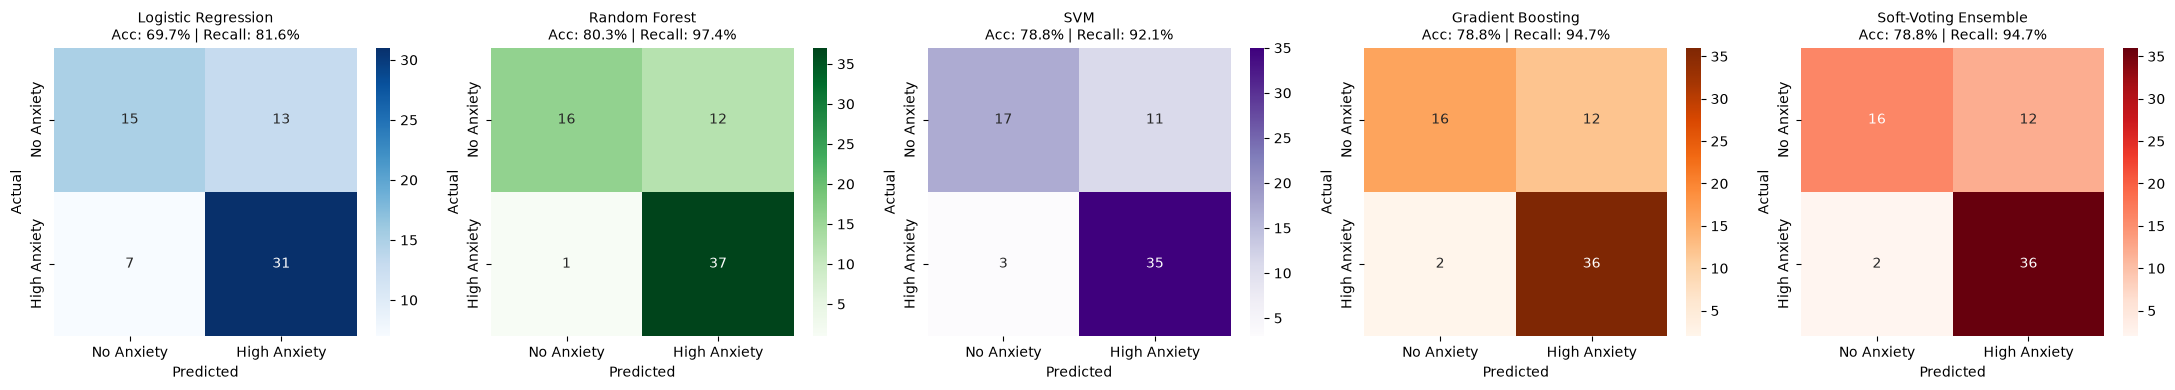

In [19]:
# Confusion matrices for all 5 models
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
model_configs = [
    (lr_model, 'Logistic Regression', 'Blues'),
    (rf_model, 'Random Forest', 'Greens'),
    (svm_model, 'SVM', 'Purples'),
    (gb_model, 'Gradient Boosting', 'Oranges'),
    (ensemble_model, 'Soft-Voting Ensemble', 'Reds')
]

for ax, (mod, name, cmap) in zip(axes, model_configs):
    preds = mod.predict(X_test)
    cm = confusion_matrix(Y_test, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap, ax=ax,
                xticklabels=['No Anxiety', 'High Anxiety'],
                yticklabels=['No Anxiety', 'High Anxiety'])
    acc = accuracy_score(Y_test, preds) * 100
    rec = recall_score(Y_test, preds) * 100
    ax.set_title(f"{name}\nAcc: {acc:.1f}% | Recall: {rec:.1f}%", fontsize=10)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()

In [20]:
# Classification report for best model (Random Forest)
rf_preds = rf_model.predict(X_test)
print("Classification Report for Best Model (Random Forest):")
print(classification_report(Y_test, rf_preds, target_names=['No Anxiety', 'High Anxiety']))

Classification Report for Best Model (Random Forest):
              precision    recall  f1-score   support

  No Anxiety       0.94      0.57      0.71        28
High Anxiety       0.76      0.97      0.85        38

    accuracy                           0.80        66
   macro avg       0.85      0.77      0.78        66
weighted avg       0.83      0.80      0.79        66



In [21]:
# Test patient predictions using real test data (no manual typing)
def predict_patient(patient_data, name):
    pred = rf_model.predict(patient_data)[0]
    prob = rf_model.predict_proba(patient_data)[0][1] * 100
    ens_pred = ensemble_model.predict(patient_data)[0]
    ens_prob = ensemble_model.predict_proba(patient_data)[0][1] * 100
    
    rf_res = "High Anxiety" if pred == 1 else "No Anxiety"
    ens_res = "High Anxiety" if ens_pred == 1 else "No Anxiety"
    
    print(f"{name}:")
    print(f"  Random Forest (Best Individual) : {rf_res} ({prob:.1f}% confidence)")
    print(f"  Voting Ensemble (Best Consensus): {ens_res} ({ens_prob:.1f}% confidence)")

predict_patient(X_test.iloc[[0]], "Patient 1")
predict_patient(X_test.iloc[[1]], "Patient 2")

Patient 1:
  Random Forest (Best Individual) : High Anxiety (56.4% confidence)
  Voting Ensemble (Best Consensus): High Anxiety (63.8% confidence)
Patient 2:
  Random Forest (Best Individual) : High Anxiety (67.5% confidence)
  Voting Ensemble (Best Consensus): High Anxiety (63.4% confidence)


In [22]:
# Overall performance summary
print(f"Logistic Regression Accuracy: {lr_test_acc:.1f}%")
print(f"Random Forest Accuracy      : {rf_test_acc:.1f}%")
print(f"SVM Accuracy                : {svm_test_acc:.1f}%")
print(f"Gradient Boosting Accuracy  : {gb_test_acc:.1f}%")
print(f"Voting Ensemble Accuracy    : {ens_test_acc:.1f}%")
print("-" * 50)
print(f"Best Test Accuracy          : {rf_test_acc:.1f}% (Random Forest)")
print(f"Highest Detection Recall    : {recall_score(Y_test, rf_preds)*100:.1f}% (Random Forest - 37/38 detected)")
print(f"Highest ROC-AUC Ranking     : {roc_auc_score(Y_test, svm_model.predict_proba(X_test)[:, 1])*100:.1f}% (SVM)")

Logistic Regression Accuracy: 69.7%
Random Forest Accuracy      : 80.3%
SVM Accuracy                : 78.8%
Gradient Boosting Accuracy  : 78.8%
Voting Ensemble Accuracy    : 78.8%
--------------------------------------------------
Best Test Accuracy          : 80.3% (Random Forest)
Highest Detection Recall    : 97.4% (Random Forest - 37/38 detected)
Highest ROC-AUC Ranking     : 87.0% (SVM)
